# Breast Cancer Diagnosis Prediction Using Gradient Boosting
Classify breast tumours as **Malignant (M)** or **Benign (B)** from cell-nucleus measurements
(Wisconsin Diagnostic Breast Cancer dataset) using exploratory data analysis, mutual information
and a **Gradient Boosting** classifier.

> Educational project only. Not a medical device and not for clinical use.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data

In [2]:
df = pd.read_csv("data.csv")
print(df.shape)
df.head()

(569, 32)


,id,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,diagnosis
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,2,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,3,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,4,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,5,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


## 3. Data inspection

In [3]:
df.info()
print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows :", df.duplicated().sum())
df.describe().T.head(12)

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   mean_radius              569 non-null    float64
 2   mean_texture             569 non-null    float64
 3   mean_perimeter           569 non-null    float64
 4   mean_area                569 non-null    float64
 5   mean_smoothness          569 non-null    float64
 6   mean_compactness         569 non-null    float64
 7   mean_concavity           569 non-null    float64
 8   mean_concave_points      569 non-null    float64
 9   mean_symmetry            569 non-null    float64
 10  mean_fractal_dimension   569 non-null    float64
 11  radius_error             569 non-null    float64
 12  texture_error            569 non-null    float64
 13  perimeter_error          569 non-null    float64
 14  area_error               569 non-null

,count,mean,std,min,25%,50%,75%,max
id,569.0,285.000000,164.400426,1.00000,143.00000,285.00000,427.00000,569.00000
mean_radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean_texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean_perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean_area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean_smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean_compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean_concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean_concave_points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean_symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400


## 4. Exploratory data analysis

diagnosis
B    357
M    212
Name: count, dtype: int64 

diagnosis
B    62.7
M    37.3
Name: count, dtype: float64


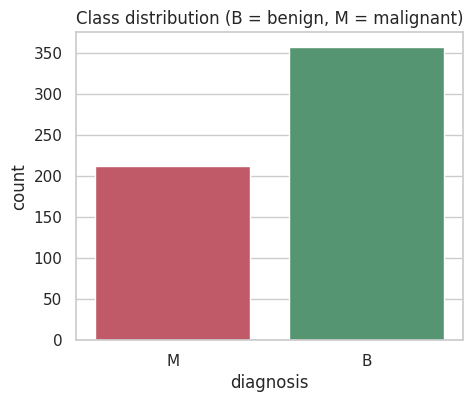

In [4]:
counts = df["diagnosis"].value_counts()
print(counts, "\n")
print((counts / len(df) * 100).round(1))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="diagnosis", palette={"B": "#4C9F70", "M": "#D1495B"})
plt.title("Class distribution (B = benign, M = malignant)")
plt.show()

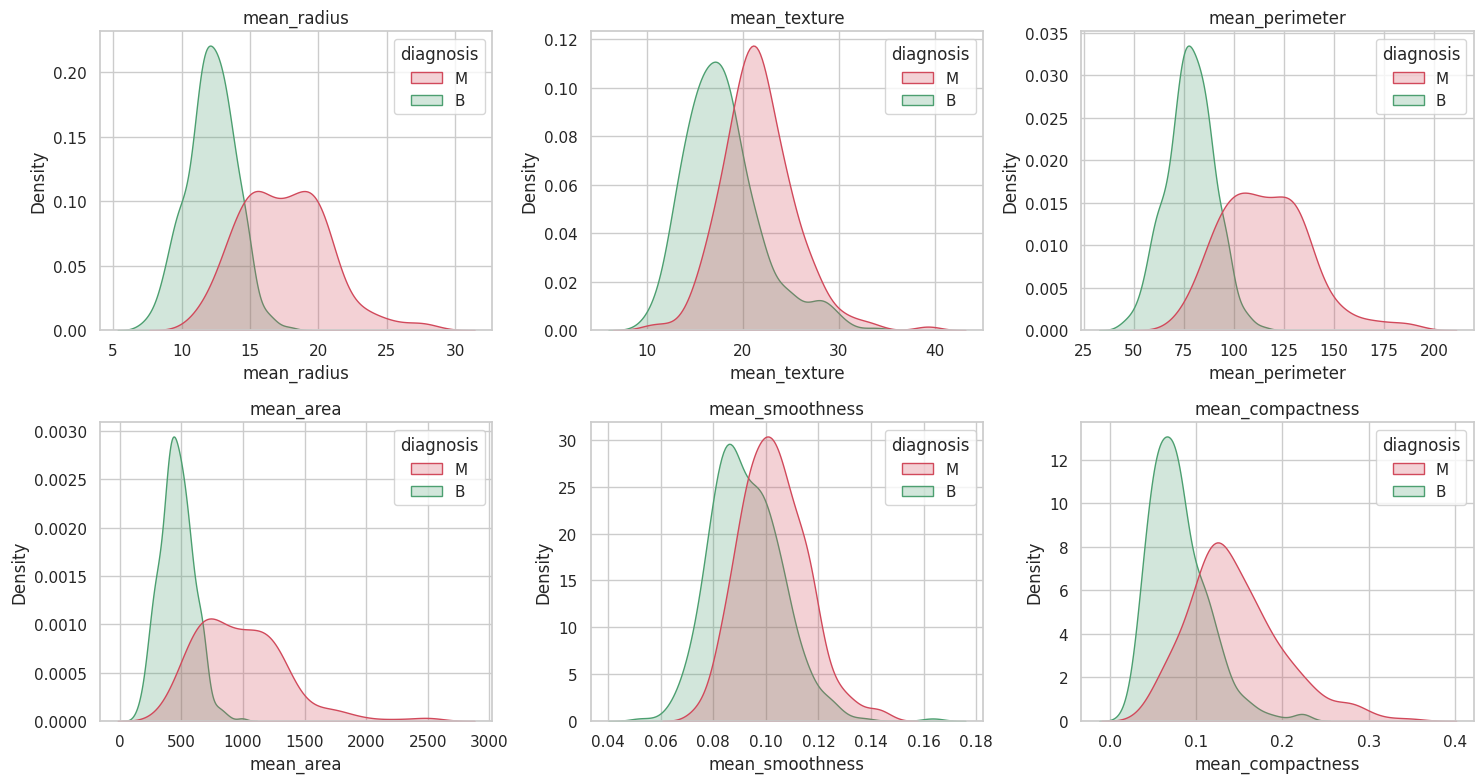

In [5]:
mean_cols = [c for c in df.columns if c.endswith("_mean") or c.startswith("mean_")]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), mean_cols[:6]):
    sns.kdeplot(data=df, x=col, hue="diagnosis", fill=True, common_norm=False,
                palette={"B": "#4C9F70", "M": "#D1495B"}, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

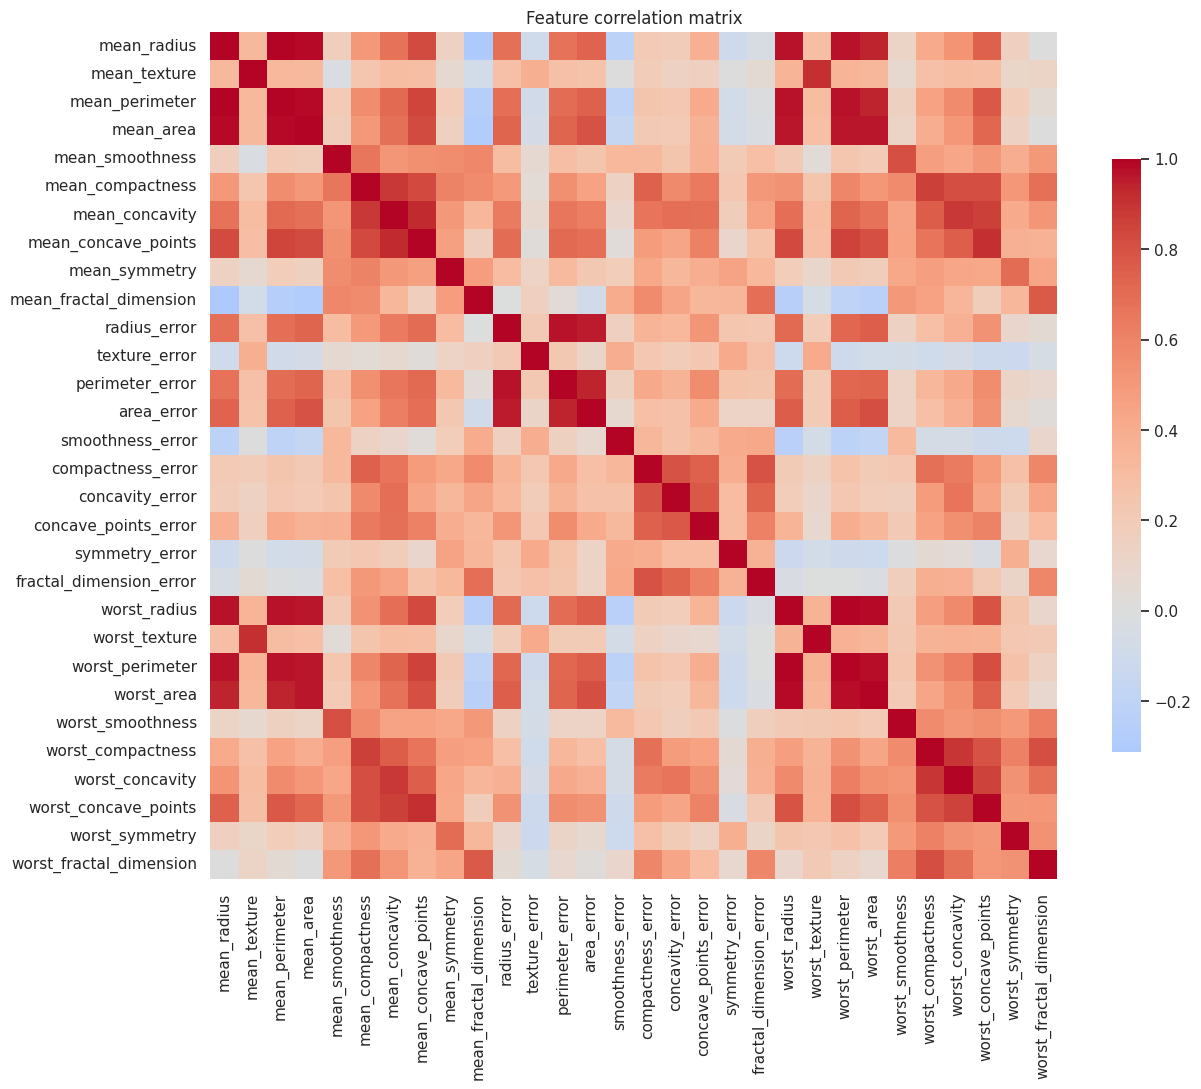

Pairs with |r| > 0.95: 15


mean_radius      mean_perimeter     0.997855
worst_radius     worst_perimeter    0.993708
mean_radius      mean_area          0.987357
mean_perimeter   mean_area          0.986507
worst_radius     worst_area         0.984015
worst_perimeter  worst_area         0.977578
radius_error     perimeter_error    0.972794
mean_perimeter   worst_perimeter    0.970387
dtype: float64

In [6]:
feature_cols = [c for c in df.columns if c not in ("id", "diagnosis")]
corr = df[feature_cols].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Feature correlation matrix")
plt.show()

# strongly correlated pairs
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().sort_values(ascending=False))
print("Pairs with |r| > 0.95:", (pairs.abs() > 0.95).sum())
pairs.head(8)

## 5. Prepare features and target

In [7]:
X = df[feature_cols]
y = (df["diagnosis"] == "M").astype(int)   # 1 = malignant, 0 = benign

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print("Malignant share  train/test:", y_train.mean().round(3), y_test.mean().round(3))

(455, 30) (114, 30)
Malignant share  train/test: 0.374 0.368


## 6. Mutual information
Mutual information measures how much each feature tells us about the diagnosis (non-linear, model-free).
Computed on the training split only to avoid leakage.

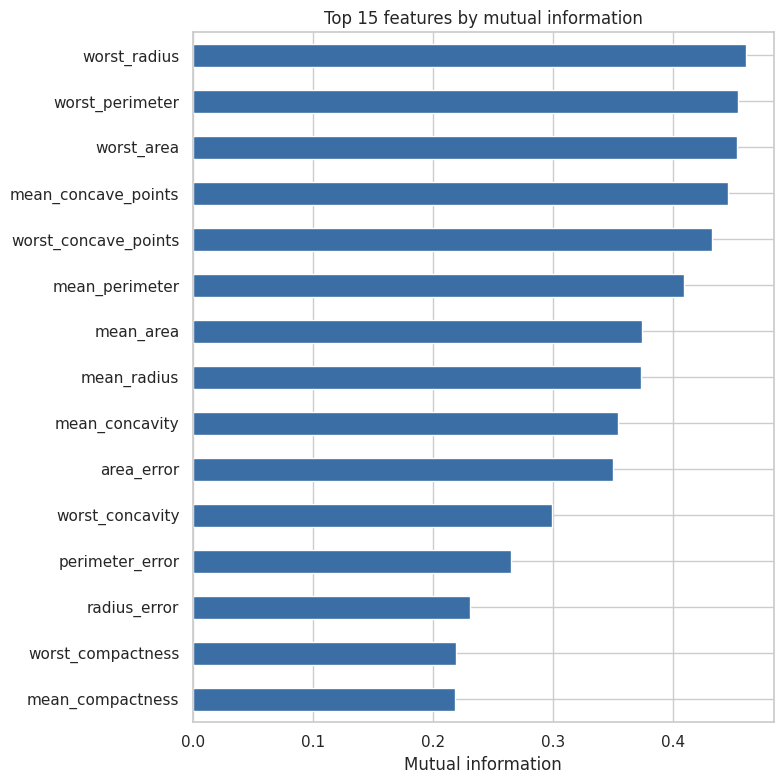

worst_radius            0.461221
worst_perimeter         0.454559
worst_area              0.453342
mean_concave_points     0.445956
worst_concave_points    0.432900
mean_perimeter          0.409301
mean_area               0.374696
mean_radius             0.373251
mean_concavity          0.354085
area_error              0.350009
dtype: float64

In [8]:
mi = pd.Series(mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE),
               index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(8, 8))
mi.head(15).sort_values().plot(kind="barh", color="#3A6EA5")
plt.title("Top 15 features by mutual information")
plt.xlabel("Mutual information")
plt.tight_layout()
plt.show()
mi.head(10)

## 7. Baseline Gradient Boosting model
Trees need no feature scaling, so none is applied.

In [9]:
gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb.fit(X_train, y_train)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(gb, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"Baseline 5-fold ROC-AUC: {cv_auc.mean():.4f} +/- {cv_auc.std():.4f}")

Baseline 5-fold ROC-AUC: 0.9908 +/- 0.0055


## 8. Hyperparameter tuning

In [10]:
param_grid = {
    "n_estimators":  [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth":     [2, 3, 4],
    "subsample":     [0.8, 1.0],
}
grid = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE),
                    param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params :", grid.best_params_)
print(f"Best CV AUC : {grid.best_score_:.4f}")
best = grid.best_estimator_

Best params : {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300, 'subsample': 1.0}
Best CV AUC : 0.9935


## 9. Evaluation on the held-out test set

In [11]:
y_pred = best.predict(X_test)
y_prob = best.predict_proba(X_test)[:, 1]

metrics = pd.Series({
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall (sensitivity)": recall_score(y_test, y_pred),
    "F1":        f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_prob),
}).round(4)
print(metrics, "\n")
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))

Accuracy                0.9649
Precision               1.0000
Recall (sensitivity)    0.9048
F1                      0.9500
ROC-AUC                 0.9934
dtype: float64 

              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



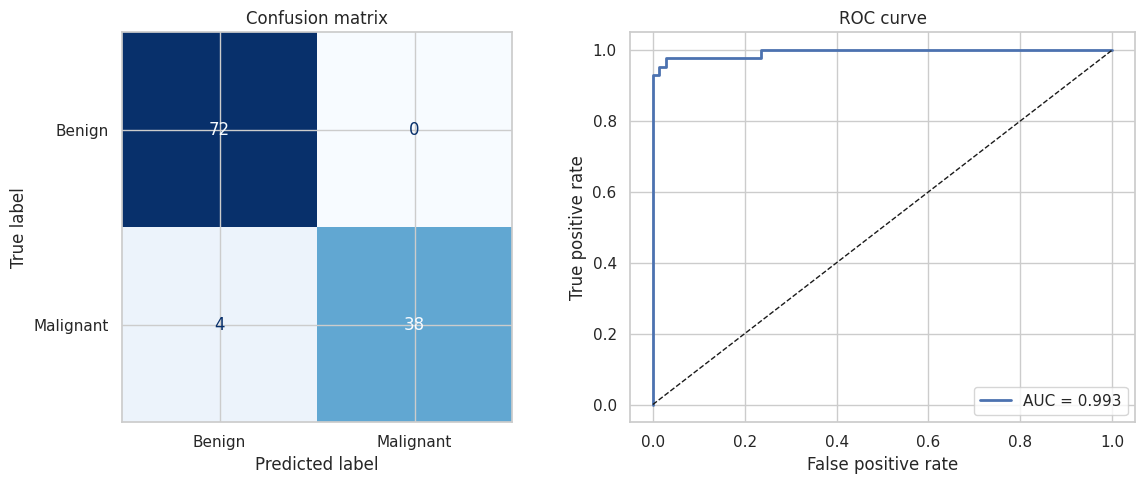

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Benign", "Malignant"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix")

fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve"); axes[1].legend()
plt.tight_layout()
plt.show()

In cancer screening a **false negative** (a malignant tumour predicted benign) is the costlier error,
so recall on the malignant class matters most. The next cell shows how the decision threshold trades
recall against precision.

In [13]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (y_prob >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_test, p),
                 "recall": recall_score(y_test, p),
                 "false_negatives": int(((p == 0) & (y_test == 1)).sum())})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,false_negatives
0,0.3,1.0,0.905,4
1,0.4,1.0,0.905,4
2,0.5,1.0,0.905,4
3,0.6,1.0,0.905,4
4,0.7,1.0,0.905,4


## 10. Feature importance

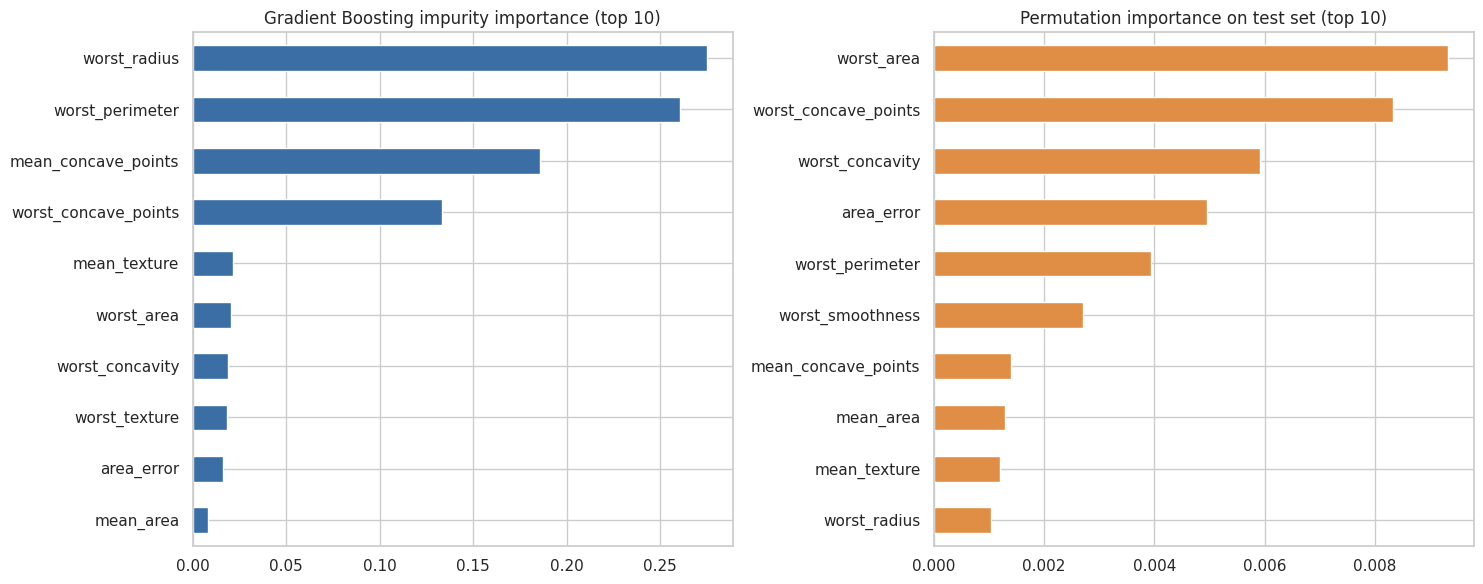

In [14]:
imp = pd.Series(best.feature_importances_, index=feature_cols).sort_values(ascending=False)
perm = permutation_importance(best, X_test, y_test, n_repeats=20,
                              random_state=RANDOM_STATE, scoring="roc_auc")
perm = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
imp.head(10).sort_values().plot(kind="barh", ax=axes[0], color="#3A6EA5")
axes[0].set_title("Gradient Boosting impurity importance (top 10)")
perm.head(10).sort_values().plot(kind="barh", ax=axes[1], color="#E08E45")
axes[1].set_title("Permutation importance on test set (top 10)")
plt.tight_layout()
plt.show()

Impurity-based importance can split credit among correlated features (many here have |r| > 0.9),
so permutation importance is shown alongside it as a cross-check.

## 11. Learning behaviour across boosting stages

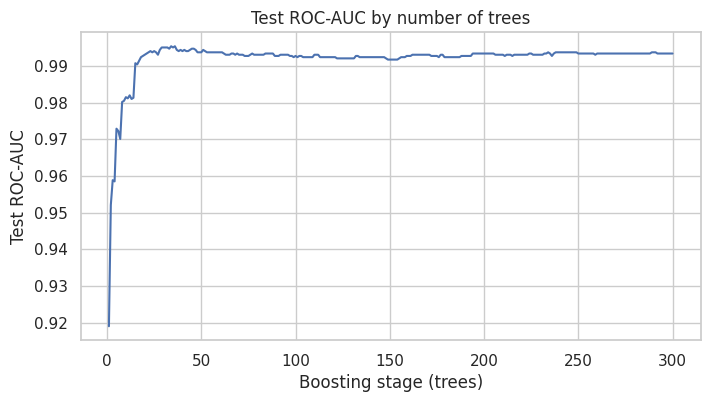

In [15]:
test_dev = [log for log in best.staged_predict_proba(X_test)]
stage_auc = [roc_auc_score(y_test, p[:, 1]) for p in test_dev]

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(stage_auc) + 1), stage_auc)
plt.xlabel("Boosting stage (trees)"); plt.ylabel("Test ROC-AUC")
plt.title("Test ROC-AUC by number of trees")
plt.show()

## 12. Predict on a new sample

In [16]:
sample = X_test.iloc[[0]]
prob = best.predict_proba(sample)[0, 1]
print(f"Predicted: {'Malignant' if prob >= 0.5 else 'Benign'}  (P(malignant) = {prob:.3f})")
print(f"Actual   : {'Malignant' if y_test.iloc[0] == 1 else 'Benign'}")

Predicted: Benign  (P(malignant) = 0.000)
Actual   : Benign


## 13. Conclusions
- The classes are moderately imbalanced (about 37% malignant), so stratified splits and ROC-AUC/recall are used.
- Size and shape features (radius, perimeter, area, concavity, concave points) carry the most signal.
- Gradient Boosting reaches high accuracy and ROC-AUC on this dataset; results on a single small test set (114 rows) have noticeable variance, so rely on cross-validated scores too.
- Next steps: compare against Random Forest / Logistic Regression, calibrate probabilities, and validate on external data.